# TC1038 · Modelación de un cohete de agua
### Jupyter Notebook — versión básica **sin clases**

**Objetivo:** comprender el ascenso, vuelo libre y descenso de un cohete de agua mediante una simulación numérica en Python. Se reutiliza el programa de la solución anterior; el único cambio estructural es sustituir la clase `Parametros` por un **diccionario**, y se presenta la gráfica directamente en Jupyter.

**Referencias exclusivas:** *Modelación de un cohete 6.pptx* y *Modelación_de_un_cohete-4.pdf*, aportados por el docente. Los valores de geometría, presión atmosférica y densidad del aire que no están medidos se indican como supuestos ilustrativos.

## Diagrama de flujo base (7 bloques)

**Inicio → Leer parámetros → Inicializar variables → Calcular fuerzas y actualizar → ¿Llegó al suelo? → Mostrar resultados y gráficas → Fin.**

La decisión regresa al cálculo hasta que el cohete aterriza. En la función `simular()` están reunidos los bloques de inicialización, cálculo y decisión.

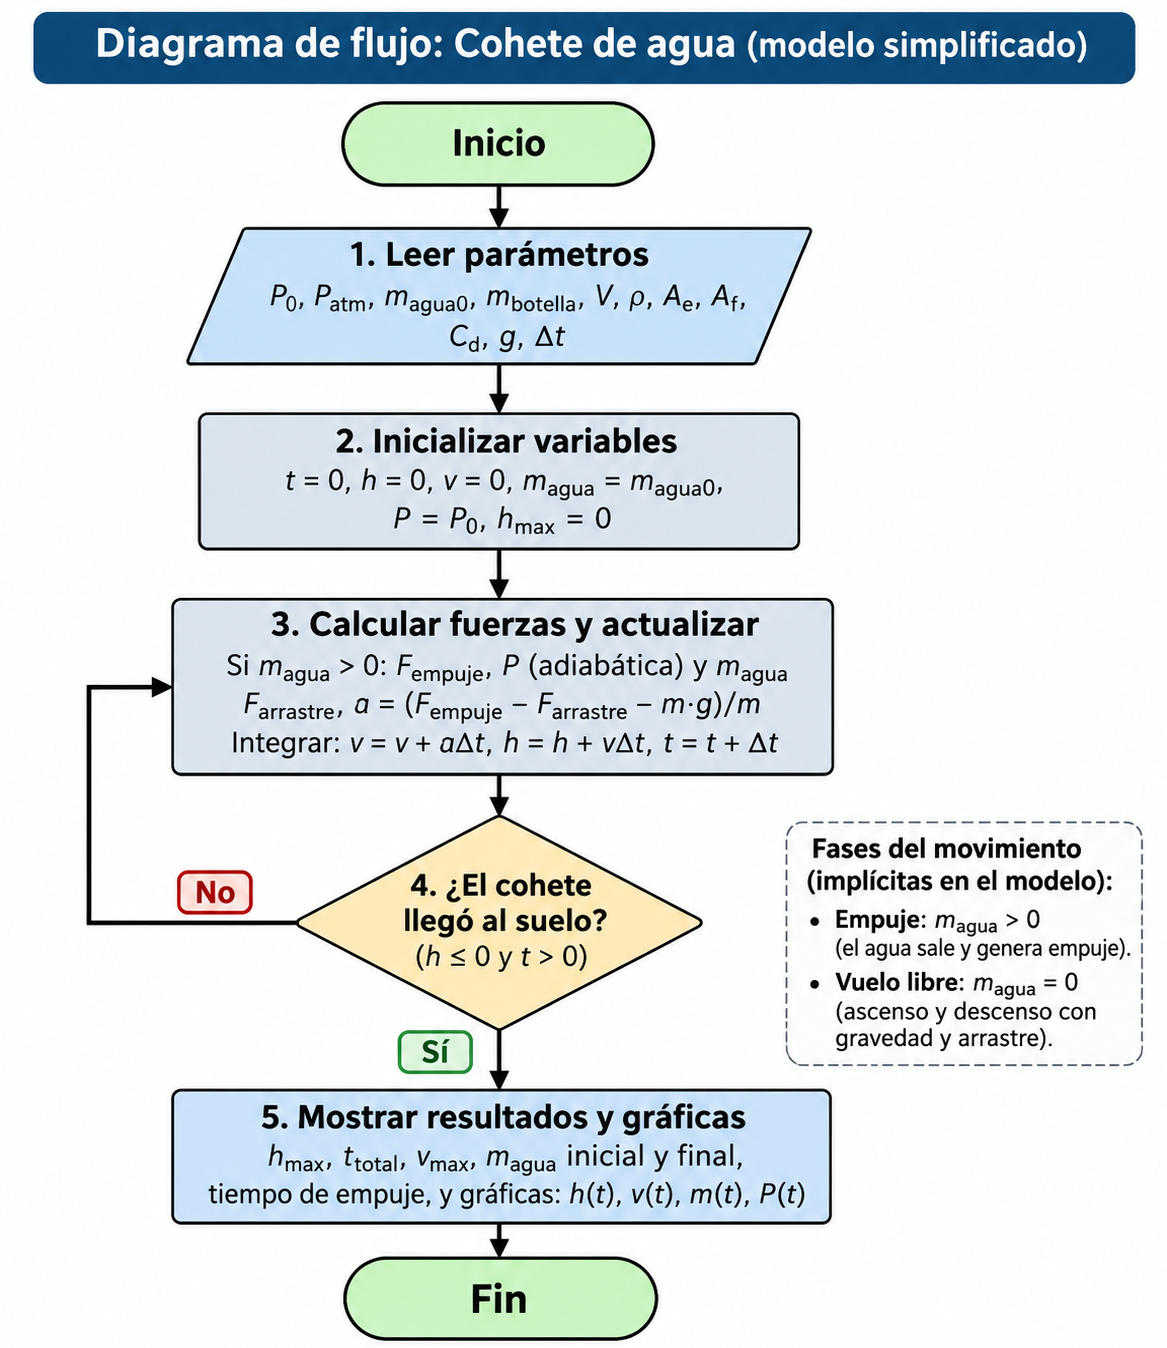

## Análisis EPS (Entrada–Proceso–Salida)

| Elemento | Descripción |
|---|---|
| **Entrada** | Presión, masas, volumen, densidades, geometría, `gamma`, gravedad y paso de tiempo. |
| **Proceso** | Validar los parámetros, obtener presión y empuje del agua, restar gravedad y arrastre, actualizar altura/velocidad/masa hasta tocar el suelo. |
| **Salida** | Altura máxima, tiempo de vuelo, velocidad máxima de ascenso, masa inicial/final de agua, duración del empuje y cuatro gráficas. |

**Etapas físicas:** (1) expulsión de agua con empuje y masa variable; (2) ascenso sin empuje; (3) descenso bajo gravedad y arrastre. Se desprecia el empuje residual del aire, como permite la simplificación descrita en las referencias.

## Bloque 1. Inicio — importar bibliotecas

Se usan las mismas bibliotecas del programa anterior, excepto `dataclasses`, que ya no se necesita. `pi` y `sqrt` sirven para áreas y velocidad de salida; `matplotlib` dibuja resultados.

In [1]:
from math import pi, sqrt
import matplotlib.pyplot as plt

PSI_A_PA = 6894.757293168  # factor de conversión: psi a pascales

## Bloque 2. Leer los parámetros

Los parámetros se guardan en un diccionario sencillo llamado `parametros`. Para consultar un dato se escribe, por ejemplo, `parametros["masa_agua_inicial"]`. Este reemplaza directamente a la clase de la versión previa, **sin alterar los valores físicos**.

> Los valores identificados como supuestos deben sustituirse por los datos experimentales del cohete del equipo.

In [2]:
# Parámetros del documento de referencia y valores ilustrativos (no son mediciones reales).
parametros = {
    "presion_manometrica_psi": 60.0,  # psi; referencia del PDF
    "masa_agua_inicial": 0.60,          # kg; referencia del PDF
    "volumen_total": 0.002,           # m³; botella ilustrativa de 2 L
    "densidad_agua": 1000.0,          # kg/m³
    "gamma": 1.4,                     # expansión adiabática
    "gravedad": 9.81,                 # m/s²
    "presion_atmosferica": 78000.0,   # Pa; supuesto, NO medición de Toluca
    "masa_botella_vacia": 0.15,       # kg; supuesto
    "densidad_aire": 1.10,            # kg/m³; supuesto, NO medición de Toluca
    "diametro_boquilla": 0.009,       # m; supuesto
    "diametro_frontal": 0.105,        # m; supuesto
    "coeficiente_arrastre": 0.50,     # supuesto
    "dt": 0.0005,                     # s; paso numérico
    "tiempo_maximo": 120.0,           # s; límite numérico
}

### Función `validar(p)`

**Recibe:** `p` (diccionario con parámetros). **Devuelve:** `None` si son válidos; en caso contrario produce `ValueError`. Comprueba presiones, masas, volúmenes, densidades, dimensiones y tiempos.

In [3]:
def validar(p):
    """Valida los parámetros físicos de la simulación.

    Recibe:
        p (dict): valores físicos y numéricos de entrada.
    Devuelve:
        None.
    Errores:
        ValueError si encuentra parámetros incompatibles.
    """
    if p["presion_manometrica_psi"] <= 0 or p["presion_atmosferica"] <= 0:
        raise ValueError("Las presiones deben ser positivas.")
    if p["masa_agua_inicial"] <= 0 or p["masa_botella_vacia"] <= 0:
        raise ValueError("Las masas deben ser positivas.")
    if p["densidad_agua"] <= 0 or p["densidad_aire"] <= 0:
        raise ValueError("Las densidades deben ser positivas.")
    if not (0 < p["masa_agua_inicial"] / p["densidad_agua"] < p["volumen_total"]):
        raise ValueError("El agua debe ocupar menos volumen que la botella.")
    if p["gamma"] <= 1 or p["gravedad"] <= 0 or p["dt"] <= 0 or p["tiempo_maximo"] <= 0:
        raise ValueError("Gamma, gravedad y tiempos no son válidos.")
    if p["diametro_boquilla"] <= 0 or p["diametro_frontal"] <= 0 or p["coeficiente_arrastre"] < 0:
        raise ValueError("Revise diámetros y coeficiente de arrastre.")

## Bloques 3, 4 y 5. Inicializar, actualizar y verificar aterrizaje

### Función `simular(p)`

**Recibe:** `p` (diccionario de parámetros). **Devuelve:** un diccionario con listas de tiempo, altura, velocidad, masa de agua, masa total y presión absoluta, además de máximos y tiempos de vuelo y empuje.

**Secuencia de cálculo:**
1. Inicializar `t = 0`, `h = 0`, `v = 0`, `m_agua = masa_agua_inicial` y las listas para registrar datos.
2. Calcular la presión absoluta mediante expansión adiabática; mientras hay agua y diferencia de presión, obtener la salida de agua y el empuje.
3. Calcular gravedad y arrastre cuadrático, que cambia de signo según la dirección de la velocidad.
4. Actualizar velocidad, altura, tiempo y agua restante con **Euler semiimplícito** (mismas expresiones del programa anterior).
5. Repetir el `while` hasta `h <= 0` después del despegue; terminar con `break`. El límite de tiempo evita una simulación sin fin.

**Importante:** el programa no incluye empuje residual de aire. La presión interna absoluta continúa registrada tras agotarse el agua y no se iguala artificialmente a la atmosférica.

In [4]:
def simular(p):
    """Simula el vuelo desde el despegue hasta el aterrizaje.

    Recibe:
        p (dict): parámetros físicos y paso de integración.
    Devuelve:
        dict: series de tiempo, altura, velocidad, masa y presión,
              además de valores máximos y tiempos característicos.
    Errores:
        ValueError o RuntimeError según validación o terminación.
    """
    validar(p)
    area_boquilla = pi * (p["diametro_boquilla"] / 2) ** 2
    area_frontal = pi * (p["diametro_frontal"] / 2) ** 2
    presion_inicial_abs = p["presion_atmosferica"] + p["presion_manometrica_psi"] * PSI_A_PA
    volumen_aire_inicial = p["volumen_total"] - p["masa_agua_inicial"] / p["densidad_agua"]

    t, h, v, m_agua = 0.0, 0.0, 0.0, p["masa_agua_inicial"]
    t_hist, h_hist, v_hist = [t], [h], [v]
    ma_hist, masa_total_hist, p_hist = [m_agua], [p["masa_botella_vacia"] + m_agua], [presion_inicial_abs]
    t_fin_empuje = 0.0
    empuje_terminado = False
    altura_maxima = 0.0
    velocidad_maxima = 0.0

    while t < p["tiempo_maximo"]:
        masa_total = p["masa_botella_vacia"] + m_agua
        # Ecuación adiabática: usar presiones ABSOLUTAS.
        vol_aire = p["volumen_total"] - m_agua / p["densidad_agua"]
        presion_abs = presion_inicial_abs * (volumen_aire_inicial / vol_aire) ** p["gamma"]
        delta_p = max(0.0, presion_abs - p["presion_atmosferica"])

        # Expulsión de agua: Bernoulli + cantidad de movimiento.
        empuje = 0.0
        flujo_masico = 0.0
        if m_agua > 0 and delta_p > 0:
            velocidad_salida = sqrt(2 * delta_p / p["densidad_agua"])
            flujo_masico = p["densidad_agua"] * area_boquilla * velocidad_salida
            empuje = flujo_masico * velocidad_salida
        elif not empuje_terminado:
            t_fin_empuje = t
            empuje_terminado = True

        # El arrastre se opone tanto al ascenso como al descenso.
        arrastre_con_signo = 0.5 * p["coeficiente_arrastre"] * p["densidad_aire"] * area_frontal * v * abs(v)
        aceleracion = (empuje - masa_total * p["gravedad"] - arrastre_con_signo) / masa_total

        # Integración numérica: primero velocidad, luego altura.
        v = v + aceleracion * p["dt"]
        h = h + v * p["dt"]
        t = t + p["dt"]
        m_agua = max(0.0, m_agua - flujo_masico * p["dt"])

        # Detectar momento de agotamiento del agua.
        if not empuje_terminado and m_agua == 0:
            t_fin_empuje = t
            empuje_terminado = True

        # Después del agua no se modela la expulsión residual de aire.
        # La presión interna termodinámica residual se mantiene como valor
        # calculado; NO se supone que haya caído instantáneamente a Patm.
        vol_aire_nuevo = p["volumen_total"] - m_agua / p["densidad_agua"]
        presion_registro = presion_inicial_abs * (volumen_aire_inicial / vol_aire_nuevo) ** p["gamma"]
        t_hist.append(t)
        h_hist.append(max(h, 0.0))
        v_hist.append(v)
        ma_hist.append(m_agua)
        masa_total_hist.append(p["masa_botella_vacia"] + m_agua)
        p_hist.append(presion_registro)
        altura_maxima = max(altura_maxima, h)
        velocidad_maxima = max(velocidad_maxima, v)

        # h<=0 al regresar al suelo; t>0 evita finalizar en el lanzamiento.
        if h <= 0 and t > p["dt"]:
            break
    else:
        raise RuntimeError("No se detectó aterrizaje; revise parámetros o tiempo máximo.")

    return {
        "tiempo": t_hist, "altura": h_hist, "velocidad": v_hist,
        "masa_agua": ma_hist, "masa_total": masa_total_hist, "presion_abs": p_hist,
        "altura_maxima": altura_maxima, "velocidad_maxima": velocidad_maxima,
        "tiempo_vuelo": t, "tiempo_empuje": t_fin_empuje,
        "masa_agua_inicial": p["masa_agua_inicial"], "masa_agua_final": m_agua,
        "presion_atmosferica": p["presion_atmosferica"],
    }

## Bloque 6. Mostrar resultados y gráficas

### Función `graficar(r, carpeta="recursos")`

**Recibe:** `r` (diccionario devuelto por `simular()`); `carpeta` (nombre de carpeta). **Devuelve:** `None`. Guarda y muestra las cuatro gráficas: altura, velocidad, masa total del cohete y presión interna absoluta frente al tiempo.

**Única adaptación visual para Jupyter:** `plt.show()` en vez de `plt.close(fig)`. La generación de los archivos PNG permanece igual.

In [5]:
def graficar(r, carpeta="recursos"):
    """Guarda en PNG y muestra cuatro gráficas en Jupyter.

    Recibe:
        r (dict): resultados de simular().
        carpeta (str): directorio de imágenes, por defecto recursos.
    Devuelve:
        None.
    """
    from pathlib import Path
    Path(carpeta).mkdir(parents=True, exist_ok=True)
    series = [
        ("altura", "Altura (m)", "01_altura.png"),
        ("velocidad", "Velocidad vertical (m/s)", "02_velocidad.png"),
        ("masa_total", "Masa total del cohete (kg)", "03_masa.png"),
        ("presion_abs", "Presión interna absoluta (Pa)", "04_presion.png"),
    ]
    for clave, ylabel, filename in series:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(r["tiempo"], r[clave], linewidth=1.8)
        ax.set_xlabel("Tiempo (s)")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel} vs. tiempo")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(Path(carpeta) / filename, dpi=150)
        plt.show()

### Función `main()`

**Recibe:** ningún argumento. Usa el diccionario `parametros`. **Devuelve:** `None`; imprime los seis indicadores y llama a la función de gráficas. Se conserva el contenido de la función coordinadora, excepto la creación de una instancia de la clase, que ya no existe.

In [6]:
def main():
    """Ejecuta y presenta la simulación.

    Recibe: ningún argumento; utiliza el diccionario `parametros`.
    Devuelve: None; imprime los resultados y dibuja cuatro gráficas.
    """
    resultados = simular(parametros)
    print("RESULTADOS DE LA SIMULACIÓN (parámetros ilustrativos)")
    print(f"Altura máxima: {resultados['altura_maxima']:.2f} m")
    print(f"Tiempo total de vuelo: {resultados['tiempo_vuelo']:.3f} s")
    print(f"Velocidad máxima de ascenso: {resultados['velocidad_maxima']:.2f} m/s")
    print(f"Masa inicial de agua: {resultados['masa_agua_inicial']:.3f} kg")
    print(f"Masa final de agua: {resultados['masa_agua_final']:.6f} kg")
    print(f"Duración del empuje: {resultados['tiempo_empuje']:.3f} s")
    graficar(resultados)

## Bloque 7. Fin — ejecutar la simulación

Ejecuta las celdas en orden, de arriba hacia abajo. La siguiente celda sustituye a `if __name__ == "__main__":` que se usaba en el archivo `.py`.

In [7]:
main()

RESULTADOS DE LA SIMULACIÓN (parámetros ilustrativos)
Altura máxima: 37.50 m
Tiempo total de vuelo: 5.781 s
Velocidad máxima de ascenso: 33.09 m/s
Masa inicial de agua: 0.600 kg
Masa final de agua: 0.000000 kg
Duración del empuje: 0.388 s


## Interpretación y comprobación

- **Altura:** inicia en cero, aumenta durante el ascenso y vuelve al suelo.
- **Velocidad:** es positiva al subir y negativa al descender.
- **Masa total:** disminuye mientras sale agua y después permanece constante.
- **Presión absoluta:** disminuye durante la expansión del aire; el modelo omite el empuje residual cuando acaba el agua.

### Preguntas para el estudiante

1. ¿Por qué es necesario actualizar la masa del cohete durante el empuje?
2. ¿Qué ocurre con la fuerza de arrastre cuando la velocidad se vuelve negativa?
3. ¿Qué condición detiene el ciclo `while` y por qué no debe detenerse cuando la velocidad vale cero?
4. ¿Qué parámetros del diccionario se deben cambiar para utilizar mediciones del lanzamiento?

**Nota:** los números obtenidos son ilustrativos. No deben confundirse con los resultados de la presentación ni con observaciones del video.